# Fisher e DALI
## A persistência da não gaussianidade

**Igor Stellet · Estatística Bayesiana · Doutorado no CBPF · 2026/2**

**Tema:** Higher-order Fisher Matrix (DALI).

Este será o notebook principal do projeto, contendo todas as hipóteses, deduções, exxemplos, aplicações e discussções dos resultados. As funções principais e que acredito que serão úteis para outros projetos serão acrescentadas em `src/dali.py`.

O planejamento está no [README](README.md).

O título *A persistência da não gaussianidade*  é inspirada na obra *A Persistência da Memória*, de Salvador Dalí (1931), [registrada no MoMA](https://www.moma.org/collection/works/79018). Ao final do projeto, farei uma oficina visual, presente no Bloco 7, para ilustrar a obra e o motivo do artista da nome ao método :), utilizando uma construção matemática própria.

# 0. Leitura e execução

O percurso de cada seção será: **pergunta → modelo e hipóteses → dedução → implementação → verificação → interpretação**.

1. Abra este arquivo com o kernel **Análise Bayesiana (.venv)** do repositório.
2. Execute a configuração abaixo, a partir da raiz do repositório ou da pasta `projeto/`.
3. Nas próximas versões, as análises serão acrescentadas na ordem do sumário e os parâmetros de execução serão documentados nos próprios blocos.

O único código científico executado para esta entrega é a figura de orientação do README, cujo script acompanha os arquivos. O módulo principal está preparado para receber as funções; ainda não implementa as aproximações.


In [2]:
from pathlib import Path
import sys

# Aceita iniciar o kernel na raiz do repositório ou na pasta deste notebook.
candidatos = (Path.cwd(), Path.cwd() / "projeto")
PROJETO_DIR = next(
    (pasta.resolve() for pasta in candidatos if (pasta / "src" / "dali.py").is_file()),
    None,
)
if PROJETO_DIR is None:
    raise FileNotFoundError(
        "Abra o notebook na pasta projeto/ ou na raiz do repositório, "
        "mantendo src/dali.py junto dos arquivos do projeto."
    )

if str(PROJETO_DIR) not in sys.path:
    sys.path.insert(0, str(PROJETO_DIR))

from src import dali

FIGURAS_DIR = PROJETO_DIR / "figuras"
DADOS_DIR = PROJETO_DIR / "data"
TABELAS_DIR = PROJETO_DIR / "tabelas"
SEMENTE = 2026

print("Pasta do projeto localizada:", PROJETO_DIR.name)
print("Módulo local carregado:", dali.__name__)
print("Estrutura inicial pronta; análises científicas a desenvolver.")


Pasta do projeto localizada: projeto
Módulo local carregado: src.dali
Estrutura inicial pronta; análises científicas a desenvolver.


## Sumário

- [1. Modelo probabilístico e Fisher](#bloco-1)
- [2. Hierarquia de DALI](#bloco-2)
- [3. Exemplos controlados](#bloco-3)
- [4. Aplicação à Lista 3](#bloco-4)
- [5. Supernovas](#bloco-5)
- [6. BAO e combinação de observáveis](#bloco-6)
- [7. Oficina visual inspirada em Dalí](#bloco-7)
- [8. Precisão e custo computacional](#bloco-8)
- [9. Síntese, limitações e referências](#bloco-9)


<a id="bloco-1"></a>

# 1. Modelo probabilístico e Fisher

Antes de aprendermos o método de DALI, é necessário entendermos o básico sobre Fisher e seu método aproximativo. Assim, podemos começar nos perguntando:

O que estamos aproximando ao usar Fisher, quais são as hipóteses e como essa matriz está relacionada com a incerteza dos parâmetros?

Antes de tentar ir além da aproximação gaussiana, vamos construir um caso em que ela funciona exatamente, ou seja, na qual a matriz de Fisher descreve completamente o problema. 

Partiremos de um modelo de medição, escreveremos a distribuição dos erros e derivaremos a likelihood. A solução analítica será confrontada com uma integração numérica da posterior, no código.

Depois manteremos a likelihood e mudaremos a informação anterior: primeiro uma prior gaussiana informativa, depois uma fronteira física que delimita a prior, isso ajuda a ver a limitação dessa aproximação. Por fim, usaremos um modelo não linear para mostrar que **erros gaussianos não implicam uma posterior gaussiana nos parâmetros**, aqui vemos quando essa aproximação começa a falhar e motiva o DALI.

Para entender isso melhor vamos:

    1. Construir um modelo de medição;
    2. Construir a likelihood a partir do modelo;
    3. Mostrar a aproximação de Fisher
    4. Discutir a interpretação física, covariância e geometria
    5. Confrontar a aproximação com integração numérica
    6. Prior e limites da aproximação.
    7. Motivar DALI

## 1.1. Modelo de medições. 

Vamos considerar medidas da posição de um corpo em MRU (com motivação de física 1). Os instantes $t_i$ são conhecidos com precisão suficiente para que sua incerteza seja desprezível neste exemplo. O modelo físico da posição prevê:

$$
\mu_i(a,v)=a+v t_i,
$$

onde $a$ é a posição no instante $t=0$ e $v$ é a velocidade. O modelo é **linear nos parâmetros** que são $a$ e $v$. É importante entender que linearidade dos parâmetros é diferente de linearidade em outras variáveis: um modelo como $a_0+a_1t+a_2t^2$ também seria linear em seus parâmetros, embora sua curva em função de $t$ fosse uma parábola (não linear).

As medidas contêm erro:

$$
d_i=\mu_i(a,v)+\varepsilon_i.
$$

A notação utilizada é:
| Símbolo | Significado | Dimensão ou unidade |
|---|---|---|
| $N$ | Número de medidas. | Inteiro. |
| $t_i$ | Instante da medida $i$. | Segundo. |
| $d\in\mathbb R^N$ | Vetor das posições observadas. | Metro. |
| $\theta=(a,v)^T$ | Parâmetros que queremos inferir. | Metro e metro por segundo. |
| $\mu(\theta)$ | Vetor das posições previstas. | Metro. |
| $\varepsilon=d-\mu(\theta)$ | Vetor dos erros no modelo de medição. | Metro. |
| $C$ | Covariância conhecida dos erros dos **dados**. | Matriz $N\times N$, em metro quadrado. |
| $\mathcal L(\theta)=p(d\mid\theta,I)$ | Likelihood dos dados observados. | Densidade em dados. |
| $\pi(\theta)=p(\theta\mid I)$ | Prior dos parâmetros. | Densidade em parâmetros. |
| $p(\theta\mid d,I)$ | Posterior dos parâmetros. | Densidade em parâmetros. |
| $\Sigma$ | Covariância dos **parâmetros** sob uma posterior especificada. | Matriz $2\times2$, com unidades por entrada. |

$I$ reúne as hipóteses e informações que condicionamos aos dados: modelo do movimento, descrição dos erros e escolhas de prior. A partir daqui, irei omitir $I$ algumas vezes para simplificar a escrita.

### Hipóteses deste exemplo

- Forma do modelo conhecida; inferimos seus parâmetros.
- O vetor dos erros é gaussiano, tem média zero e covariância $C$ conhecida.
- $C$ é simétrica, definida positiva e **independente dos parâmetros**.

In [3]:
import importlib
import platform

import numpy as np
import pandas as pd
import scipy
from scipy.integrate import simpson
from scipy.stats import norm, chi2, multivariate_normal
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Recarregar ajuda durante a reescrita das funções em src/dali.py.
importlib.reload(dali)

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "svg.fonttype": "none",
})
AZUL, LARANJA, VERDE, CINZA = "#245f94", "#b45f2c", "#398477", "#777777"
FIGURAS_B1 = FIGURAS_DIR / "bloco_01"
TABELAS_B1 = TABELAS_DIR / "bloco_01"
FIGURAS_B1.mkdir(parents=True, exist_ok=True)
TABELAS_B1.mkdir(parents=True, exist_ok=True)

def mostrar_tabela(nome, tabela):
    """Exibe e exporta a mesma tabela usada na discussão."""
    tabela.to_csv(TABELAS_B1 / f"{nome}.csv", index=False)
    display(tabela)

def mostrar_figura(nome, figura):
    """Preserva uma versão estática no notebook e arquivos para reutilização."""
    for formato in ("png", "svg"):
        figura.savefig(FIGURAS_B1 / f"{nome}.{formato}", dpi=170, bbox_inches="tight")
    display(figura)
    plt.close(figura)

print("Python:", platform.python_version())
print("NumPy:", np.__version__, "| SciPy:", scipy.__version__)


Python: 3.14.4
NumPy: 2.5.4 | SciPy: 1.18.1


### Erro de calibração compartilhado

Para que a distinção entre as covariâncias tenha um significado físico, vamos simular

$$
\varepsilon_i=b_{\rm cal}+\eta_i,
\qquad b_{\rm cal}\sim\mathcal N(0,\tau_{\rm cal}^2),
\qquad \eta_i\sim\mathcal N(0,\sigma_i^2).
$$

O deslocamento $b_{\rm cal}$ é compartilhado por todas as medidas, um erro sistemático, enquanto os $\eta_i$ são independentes entre si e de $b_{\rm cal}$. Ao integrar sobre essa incerteza de calibração, o vetor dos erros continua gaussiano e sua covariância é

$$
C_{ij}=\mathbb E[\varepsilon_i\varepsilon_j]
=\tau_{\rm cal}^2+\sigma_i^2\delta_{ij},
$$

onde $\delta_{ij}=1$ para $i=j$ e zero caso contrário. No ajuste, $\tau_{\rm cal}$ e os $\sigma_i$ serão considerados conhecidos. O erro compartilhado  permanece na incerteza descrita por $C$.


In [4]:
rng_b1 = np.random.default_rng(SEMENTE)
t = np.linspace(0.0, 4.0, 13)                         # segundos
N = t.size
sigma_ind = 0.20 + 0.08*t/4.0                        # metros
tau_cal = 0.10                                      # metros
C_ind = np.diag(sigma_ind**2)
C_dados = C_ind + tau_cal**2*np.ones((N, N))
X = np.column_stack((np.ones(N), t))                 # mu = X @ theta
theta_gerador = np.array([1.20, 0.020])              # m; m/s

# Cholesky produz uma realização com a covariância total desejada.
L_dados = np.linalg.cholesky(C_dados)
erro = L_dados @ rng_b1.normal(size=N)
dados = X @ theta_gerador + erro

mostrar_tabela("01_dados_simulados", pd.DataFrame({
    "t [s]": t, "d [m]": dados,
    "sigma independente [m]": sigma_ind,
    "sigma total marginal [m]": np.sqrt(np.diag(C_dados)),
}))
pd.DataFrame(C_dados).to_csv(TABELAS_B1/"01_covariancia_dados.csv", index=False)


,t [s],d [m],sigma independente [m],sigma total marginal [m]
0,0.000000,1.022652,0.200000,0.223607
1,0.333333,1.225372,0.206667,0.229589
2,0.666667,0.752947,0.213333,0.235608
3,1.000000,1.462333,0.220000,0.241661
4,1.333333,1.330881,0.226667,0.247745
5,1.666667,1.128663,0.233333,0.253859
6,2.000000,1.123027,0.240000,0.260000
7,2.333333,1.279281,0.246667,0.266166
8,2.666667,1.143595,0.253333,0.272356
9,3.000000,1.155865,0.260000,0.278568


## 1.2. Construindo a likelihood

A hipótese estatística é uma distribuição para os **erros dos dados**, que nos diz que:

$$
p(\varepsilon)=\frac{1}{(2\pi)^{N/2}|C|^{1/2}}
\exp\!\left[-\frac12\varepsilon^TC^{-1}\varepsilon\right].
$$

Fixados os parâmetros, a mudança de variável $d=\mu(\theta)+\varepsilon$ é uma translação e tem jacobiano unitário. Portanto,

$$
\boxed{\mathcal L(\theta)=p(d\mid\theta)=
\frac{1}{(2\pi)^{N/2}|C|^{1/2}}
\exp\!\left[-\frac12r(\theta)^TC^{-1}r(\theta)\right]},
\qquad r(\theta)=d-\mu(\theta).
$$

Agora $d$ está fixado no valor observado e investigamos como a densidade dos dados muda com $\theta$. A likelihood não é normalizada nos parâmetros e devemos tomar cuidado com iisso. A posterior será dada por:

$$
p(\theta\mid d)=\frac{\mathcal L(\theta)\pi(\theta)}{Z},
\qquad Z=\int \mathcal L(\theta)\pi(\theta)\,d\theta.
$$

Definindo $\chi^2(\theta)=r^TC^{-1}r$, temos

$$
-\log\mathcal L=\frac12\chi^2+
\frac N2\log(2\pi)+\frac12\log|C|.
$$

Como $C$ é fixa, os dois últimos termos são constantes. Nós os manteremos nas avaliações normalizadas. Se $C$ dependesse de $\theta$, o determinante também contribuiria para as derivadas e para localização do máximo da Likelihood.

### A interpretação geométrica nos dados

Se $C=LL^T$ (valido para matrizes simétricas e positivas definidas), com $L$ triangular de Cholesky, então

$$
\chi^2=\|L^{-1}r\|^2.
$$

Assim, $C^{-1}$ mede distâncias no espaço dos dados de acordo com as incertezas e correlações do experimento. A matriz de convariância se importa com o tamanho da diferença entre levando em consideração se o ruído esperado permite distinguir essa diferença ou se está dentro do esperado.


## 1.3. Modelo linear: Forma quadrática exata

Escrevemos $\mu=X\theta$, com $X$ de dimensão $N\times p$ e $p=2$ neste exemplo. Cada linha é $(1,t_i)$. Expandindo o quadrado,

$$
\chi^2(\theta)=d^TC^{-1}d-2\theta^TX^TC^{-1}d
+\theta^T X^TC^{-1}X\theta.
$$

$$
\chi^2(\theta)=d^TC^{-1}d-2\theta^Tb
+\theta^T F\theta.
$$

Definimos

$$
F=X^TC^{-1}X,\qquad b=X^TC^{-1}d.
$$

Da condição $\nabla_\theta\chi^2=0$, segue o sistema das equações normais:

$$
\boxed{F\widehat\theta_{\rm ML}=b}.
$$

Para $\Delta=\theta-\widehat\theta_{\rm ML}$ podemos adicionar e subtrair esse termo nas equações acimas para obtermos:

$$
\boxed{\chi^2(\theta)=\chi^2_{\min}+\Delta^TF\Delta}.
$$

Note que nesse moodelo linear essa igualdade é exata! O quadrado do resíduo já é um polinômio de grau dois em $\theta$. Não desprezamos termos cúbicos ou de ordem superior e aproximação de Fisher torna-se a melhor possível para esse modelo.

A likelihood tem forma gaussiana nos parâmetros. Para falar de uma **posterior** gaussiana, ainda precisamos especificar a prior. Uma prior gaussiana preserva essa forma; uma prior restritiva pode cortá-la.


## 1.4. Escolha de prior e solução analítica da posterior

Vamos usar $\pi(\theta)=\mathcal N(m_0,S_0)$, onde $m_0$ é a média da prior e $S_0$ é sua covariância. Ignorando o termo da evidência que é apenas normalização, podemos somar os expoentes da likelihood e da prior, no qual obtemos
$$
Q=F+S_0^{-1},\qquad
m=Q^{-1}\left(b+S_0^{-1}m_0\right),\qquad
\boxed{\Sigma=Q^{-1}}.
$$

Logo, $p(\theta\mid d)=\mathcal N(m,\Sigma)$. Aqui, a matriz $Q$ está relacionada à precisão da **posterior**, enquanto $F$ é a informação provinda da likelihood, veja que a prior Gaussaiana desloca o máximo da posterior em realação ao máximo da Likelihood.. O estimador ML maximiza a likelihood; o MAP maximiza a posterior. A média e o MAP coincidem na distribuição gaussiana.

Começaremos por uma prior ilustrativa ampla, com desvios de $10\,\mathrm m$ em $a$ e $3\,\mathrm{m\,s^{-1}}$ em $v$. Ela é  praticamente constante na região restringida pelos dados.

No limite em que a prior se torna muito ampla, $S_0^{-1}$ torna-se muito pequeno, de modo que $m\to\widehat\theta_{\rm ML}$ e $\Sigma\to F^{-1}$. No limite dessa prior ampla vamos utilizar as Gaussianas largas, para facilitar os códigos e sua estrutura.


In [6]:
m0 = np.array([0.0, 0.0])
S0 = np.diag([10.0**2, 3.0**2])
ajuste = dali.linear_gaussian_posterior(X, dados, C_dados, m0, S0)
F = ajuste.fisher
Q = ajuste.precision
m = ajuste.mean
Sigma = ajuste.covariance
Sigma_L = np.linalg.solve(F, np.eye(2))

mostrar_tabela("02_parametros_lineares", pd.DataFrame({
    "Parâmetro": ["a [m]", "v [m/s]"],
    "Gerador (conhecido só na simulação)": theta_gerador,
    "Máxima likelihood": ajuste.mle,
    "Média/MAP posterior": m,
    "Desvio marginal posterior": np.sqrt(np.diag(Sigma)),
}))
display(Markdown("**Informação da likelihood $F$, precisão posterior $Q$ e covariância $\\Sigma$:**"))
for nome, matriz in [("F", F), ("Q", Q), ("Sigma", Sigma)]:
    display(Markdown(f"**{nome}**"))
    display(pd.DataFrame(matriz, index=["a", "v"], columns=["a", "v"]))


,Parâmetro,Gerador (conhecido só na simulação),Máxima likelihood,Média/MAP posterior,Desvio marginal posterior
0,a [m],1.20,1.082863,1.082649,0.150889
1,v [m/s],0.02,0.060574,0.060608,0.052965


**Informação da likelihood $F$, precisão posterior $Q$ e covariância $\Sigma$:**

**F**

,a,v
a,69.992634,121.725608
v,121.725608,568.017112


**Q**

,a,v
a,70.002634,121.725608
v,121.725608,568.128223


**Sigma**

,a,v
a,0.022768,-0.004878
v,-0.004878,0.002805


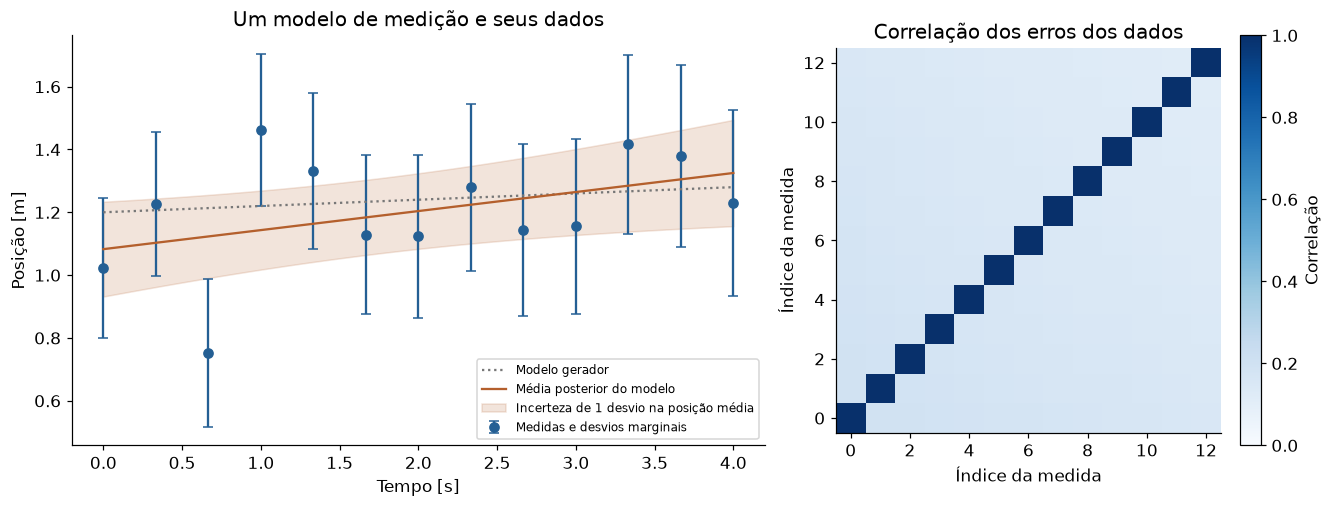

In [7]:
t_plot = np.linspace(t.min(), t.max(), 250)
X_plot = np.column_stack((np.ones(t_plot.size), t_plot))
mu_plot = X_plot @ m
sigma_modelo = np.sqrt(np.einsum("ni,ij,nj->n", X_plot, Sigma, X_plot))
corr_dados = C_dados / np.sqrt(np.outer(np.diag(C_dados), np.diag(C_dados)))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.8, 1]},
                        layout="constrained")
axs[0].errorbar(t, dados, yerr=np.sqrt(np.diag(C_dados)), fmt="o", color=AZUL,
                capsize=3, label="Medidas e desvios marginais")
axs[0].plot(t_plot, X_plot @ theta_gerador, color=CINZA, ls=":", label="Modelo gerador")
axs[0].plot(t_plot, mu_plot, color=LARANJA, label="Média posterior do modelo")
axs[0].fill_between(t_plot, mu_plot-sigma_modelo, mu_plot+sigma_modelo,
                     color=LARANJA, alpha=.17, label="Incerteza de 1 desvio na posição média")
axs[0].set(xlabel="Tempo [s]", ylabel="Posição [m]", title="Um modelo de medição e seus dados")
axs[0].legend(fontsize=8)
im = axs[1].imshow(corr_dados, vmin=0, vmax=1, cmap="Blues", origin="lower")
axs[1].set(xlabel="Índice da medida", ylabel="Índice da medida", title="Correlação dos erros dos dados")
fig.colorbar(im, ax=axs[1], label="Correlação")
mostrar_figura("01_dados_e_covariancia", fig)


As barras individuais mostram os desvios, os erros dos dados, $\sqrt{C_{ii}}$, Essa informação aparece no painel da direita.

A faixa da curva é a incerteza sobre a **posição média prevista**, calculada com $\operatorname{Var}[\mu(t)\mid d]=X(t)\Sigma X(t)^T$.

O parâmetro gerador aparece porque os dados são simulados. Num experimento real, ele não estaria disponível para julgar o ajuste.


## 1.5. Relação entre matriz de Fisher e informação

A definição de informação esperada utiliza a distribuição dos dados sob parâmetros fixos. Definindo o *score* $s_a=\partial_a\log\mathcal L$, com $a$ sendo a derivada em relação aos PARÂMETROS. 

$$
F^{\rm exp}_{ab}=\mathbb E_{d\mid\theta}[s_as_b]
=-\mathbb E_{d\mid\theta}[\partial_a\partial_b\log\mathcal L],
$$

sob as condições de regularidade que permitem diferenciar sob a integral.

Para um modelo gaussiano cuja covariância não dependa dos dados, escrevendo $\mu_{,a}=\partial_a\mu$,

$$
s_a=\mu_{,a}^TC^{-1}r.
$$

Como $\mathbb E[r]=0$ e $\mathbb E[rr^T]=C$ sob o modelo verdadeiro,

$$
\boxed{F^{\rm exp}_{ab}=\mu_{,a}^TC^{-1}\mu_{,b}},
\qquad F^{\rm exp}=J^TC^{-1}J,
$$

onde $J_{ia}=\partial_a\mu_i$. No modelo linear, $J=X$ e recuperamos a matriz já obtida pelas equações anterioresç

### Três matrizes parecidas que trazem informações diferentes

A curvatura observada da log-likelihood negativa, ou seja, considerando os dados medidos, é

$$
H^{\rm obs}_{ab}=
\mu_{,a}^TC^{-1}\mu_{,b}
-\mu_{,ab}^TC^{-1}r.
$$

No caso linear as derivadas segundas em relação ao parâmetros são todas 0, $\mu_{,ab}=0$, portanto $H^{\rm obs}=F^{\rm exp}=F$ para qualquer conjunto de dados. Num modelo não linear, o termo com o resíduo pode permanecer mesmo num máximo da likelihood, isso é importante para interpretarmos melhor o DALI, que se expande para modelos não lineares.

| Matriz | O que descreve? | Nesta aplicação linear |
|---|---|---|
| $F^{\rm exp}$ | Informação média em dados que poderiam ser observados. | $X^TC^{-1}X$. |
| $H^{\rm obs}$ | Curvatura da log-likelihood negativa nos dados observados. | Igual a $F^{\rm exp}$. |
| $H^{\rm post}$ | Curvatura de $-\log p(\theta\mid d)$ no ponto considerado. | $F+S_0^{-1}=Q$. |

Para uma posterior geral com máximo interior $\widehat\theta$,

$$
-\log p(\widehat\theta+\Delta\mid d)
\simeq -\log p(\widehat\theta\mid d)
+\frac12\Delta^TH^{\rm post}\Delta.
$$

A inversa de $H^{\rm post}$ descreve a covariância da gaussiana **local**.

In [8]:
segundas_lineares = np.zeros((N, 2, 2))
H_obs_linear = dali.observed_gaussian_hessian(
    dados-X @ ajuste.mle, X, segundas_lineares, C_dados
)
assert np.allclose(F, H_obs_linear)
assert np.allclose(Q, F + np.linalg.solve(S0, np.eye(2)))
assert np.allclose(Q @ Sigma, np.eye(2))
print("Modelo linear: informação esperada = curvatura observada.")
print("A covariância posterior é a inversa de Q = F + precisão da prior.")


Modelo linear: informação esperada = curvatura observada.
A covariância posterior é a inversa de Q = F + precisão da prior.


<a id="bloco-2"></a>

# 2. Hierarquia de DALI

**Situação: planejada.**

**Pergunta:** como reorganizar a expansão para manter os grupos de termos gerados pelas derivadas do modelo?

- [ ] Expandir o modelo em torno de um ponto explicitamente escolhido.
- [ ] Derivar singleto, dubleto e tripleto, com fatores e termos cruzados.
- [ ] Distinguir ordem da derivada e grau no expoente.
- [ ] Separar a previsão com resíduo nulo da análise de dados com resíduo preservado.
- [ ] Explicar a relação entre singleto, priors e inversão de Fisher.
- [ ] Conferir duas formas de calcular a mesma aproximação.

A forma de quadrado e as condições de normalização serão discutidas antes das aplicações.

<a id="bloco-3"></a>

# 3. Exemplos controlados

**Situação: planejada.**

**Pergunta:** em quais casos conhecemos a resposta suficiente para testar o método?

| Exemplo | O que queremos compreender |
|---|---|
| Linear gaussiano | Limite em que as ordens superiores do modelo se anulam. |
| Quadrático | Posterior curva e exatidão da expansão do modelo até segunda ordem. |
| Dependência inversa | Parametrização e um caso em que o tripleto remove um máximo espúrio. |
| Modelo polinomial de quarto grau | Um contraexemplo em que dubleto e tripleto criam máximos espúrios. |

As transformações manterão a mesma prior física. Cada candidato a modo encontrado pelas aproximações será confrontado com a likelihood completa.

![Figura de orientação: modelo quadrático](figuras/visao_geral_fisher_dali.png)

A definição do modelo, o suporte, as regiões de probabilidade e o código desta figura estão no README e em `figuras/gerar_visao_geral.py`.


<a id="bloco-4"></a>

# 4. Aplicação à Lista 3

**Situação: planejada.**

**Pergunta:** como a ordem da expansão se relaciona com as não gaussianidades observadas no exercício?

O [notebook da Lista 3](../notebooks/listas/03_lista_3.ipynb) será uma referência, mas a análise de DALI será desenvolvida aqui.

- [ ] Reconstruir a likelihood e as priors, mantendo o fator $2w^2+3$ explícito.
- [ ] Relacionar os cortes e as marginais às questões 4 e 5.
- [ ] Medir assimetria, curtose, modos e probabilidades relevantes.
- [ ] Demonstrar a identidade do modelo quadrático com sua expansão até segunda ordem.
- [ ] Discutir a diferença entre informação esperada e curvatura observada, especialmente em $y=-1$.
- [ ] Comparar $P(w>0)$ e os pesos dos modos com a referência numérica.



<a id="bloco-5"></a>

# 5. Supernovas

**Situação: planejada.**

**Pergunta:** como Fisher e DALI se comportam na aplicação observacional do artigo original?

O primeiro alvo será wCDM plano em dois parâmetros, com dados Union2.1 e escolhas documentadas de calibração, covariância, priors e ponto de expansão.

- [ ] Documentar os dados e implementar as distâncias cosmológicas.
- [ ] Validar unidades, quadratura e tratamento do deslocamento aditivo.
- [ ] Distinguir dados observados e previsão no fiducial.
- [ ] Construir uma referência numérica convergida.
- [ ] Validar as derivadas e comparar Fisher, dubleto e tripleto.
- [ ] Confrontar contornos, marginais, métricas e uma verificação por MCMC.

A reprodução será descrita em termos dos ingredientes efetivamente adotados.


<a id="bloco-6"></a>

# 6. BAO e combinação de observáveis

**Situação: planejada.**

**Pergunta:** combinar observáveis com degenerescências diferentes altera a vantagem de DALI sobre Fisher?

Vamos utilizar as medidas BAO publicadas de BOSS DR12 e sua covariância completa, com a origem em catálogos de galáxias explicitada.

- [ ] Conferir a ordem das observáveis, os redshifts e a matriz correspondente.
- [ ] Definir as convenções de $D_M$, $H$, $r_d$ e calibração.
- [ ] Explicitar as hipóteses para a combinação com supernovas.
- [ ] Construir referências e aproximações para os mesmos parâmetros e priors.
- [ ] Comparar as degenerescências e a informação dos conjuntos isolados e combinados.


<a id="bloco-7"></a>

# 7. Oficina visual inspirada em Dalí

**Situação: planejada.**

**Pergunta:** até onde uma aproximação local acompanha uma distribuição de contornos deformados?

O exemplo será construído por código, inspirado nos relógios de *A Persistência da Memória*. O modelo, a covariância, os parâmetros inferidos e a prior serão explicitados. Uma possibilidade é variar as configurações de deformação num modelo com termo quadrático e termo senoidal, descrito no README.

- [ ] Construir e normalizar a referência.
- [ ] Comparar Fisher, dubleto e tripleto do mesmo modelo.
- [ ] Investigar o efeito do ruído e do ponto de expansão.
- [ ] Produzir uma versão estática legível no GitHub.
- [ ] Acrescentar controles interativos se ajudarem a exploração.

A finalidade é ilustrar a geometria e os limites das aproximações no modelo definido.


<a id="bloco-8"></a>

# 8. Precisão e custo computacional

**Situação: planejada; as medições acompanharão os exemplos.**

**Pergunta:** quanto custa atingir determinada qualidade de aproximação e exploração?

- [ ] Separar erro da aproximação, erro de integração e erro de amostragem.
- [ ] Comparar probabilidades, momentos, quantis, modos e divergências adequadas.
- [ ] Definir regiões conjuntas por conteúdo de probabilidade.
- [ ] Medir derivadas, preparação dos coeficientes, avaliação e exploração.
- [ ] Comparar custo total e tamanho efetivo, além do tempo por avaliação.
- [ ] Identificar quando o preparo de DALI compensa ou deixa de compensar.

Fisher e DALI aproximam a função; grid e MCMC são formas de explorá-la. As comparações manterão o mesmo problema estatístico.


<a id="bloco-9"></a>

# 9. Síntese, limitações e referências

**Situação: será escrita a partir dos experimentos validados.**

A discussão final retomará a pergunta central, os regimes em que cada aproximação funcionou, as falhas observadas e os custos medidos. Os resultados não serão preenchidos antes da execução e da validação dos estudos.

## Referências iniciais

1. Sellentin, Quartin e Amendola. *Breaking the spell of Gaussianity: forecasting with higher order Fisher matrices*. [arXiv:1401.6892v3](https://arxiv.org/abs/1401.6892v3).
2. de Souza e Quartin. *On the use of the Derivative Approximation for Likelihoods for Gravitational Wave Inference*. [arXiv:2510.16955v2](https://arxiv.org/abs/2510.16955v2).
3. [Supernova Cosmology Project: Union2.1](https://supernova.lbl.gov/Union/).
4. Alam et al. *Cosmological analysis of the DR12 galaxy sample*. [arXiv:1607.03155](https://arxiv.org/abs/1607.03155), [dados BOSS](https://sdss3.org/science/boss_publications.php).
5. Gregory, *Bayesian Logical Data Analysis for the Physical Sciences*; slides e Lista 3 da disciplina de Estatística Bayesiana.
6. [MoMA: Salvador Dalí, The Persistence of Memory, 1931](https://www.moma.org/collection/works/79018).

As referências serão acrescentadas junto das deduções, escolhas de modelo e dados a que derem suporte. O roteiro completo de leituras está no README.
